In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import itertools
from imblearn.over_sampling import SMOTE
import time
from inference_utils import preprocess_and_select_25

In [2]:
PROJECT_DIR = Path(r"E:\DataMining_Group32")

NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"
if str(NOTEBOOKS_DIR) not in sys.path:
    sys.path.append(str(NOTEBOOKS_DIR))

from inference_utils import preprocess_and_select_25

RAW_SPLIT_DIR = PROJECT_DIR / "data" / "raw_split"

print("Loading raw split data...")
X_train_raw = pd.read_csv(RAW_SPLIT_DIR / "X_train_before.csv")
X_val_raw = pd.read_csv(RAW_SPLIT_DIR / "X_val_before.csv")
X_test_raw = pd.read_csv(RAW_SPLIT_DIR / "X_test_before.csv")

y_train_raw = pd.read_csv(RAW_SPLIT_DIR / "y_train.csv").squeeze("columns")
y_val = pd.read_csv(RAW_SPLIT_DIR / "y_val.csv").squeeze("columns")
y_test = pd.read_csv(RAW_SPLIT_DIR / "y_test.csv").squeeze("columns")

print("Applying preprocessing, deduplication, and selecting top 25 features...")

# 1. برای Train: هم X و هم y را می‌دهیم تا Deduplication انجام شود
X_train, y_train = preprocess_and_select_25(X_train_raw, PROJECT_DIR, y=y_train_raw)

# 2. برای Validation و Test: فقط X را می‌دهیم (بدون حذف سطر)
X_val = preprocess_and_select_25(X_val_raw, PROJECT_DIR)
X_test = preprocess_and_select_25(X_test_raw, PROJECT_DIR)

print(f"\nTrain Shape:      X={X_train.shape} | y={y_train.shape}")
print(f"Validation Shape: X={X_val.shape} | y={y_val.shape}")
print(f"Test Shape:       X={X_test.shape} | y={y_test.shape}")

Loading raw split data...
Applying preprocessing, deduplication, and selecting top 25 features...
[Deduplication] X_train before: 70,040 rows
[Deduplication] X_train after:  70,024 rows
[Deduplication] Removed: 16 duplicate rows

Train Shape:      X=(70024, 25) | y=(70024,)
Validation Shape: X=(14960, 25) | y=(14960,)
Test Shape:       X=(15000, 25) | y=(15000,)


In [3]:
smote_strategies = {
    "no_smote": None,
    "smote_1_4_to_5000": {1: 5000, 4: 5000},
    "smote_1_4_to_10000": {1: 10000, 4: 10000},
    "smote_moderate": {1: 10000, 3: 20000, 4: 10000},
}

print("\n" + "="*50)
print("STARTING EXTENDED TUNING (SMOTE Strategies + Decision Tree Params)")
print("="*50)

param_grid = {
    'max_depth': [8, 12, 16, 20],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

keys, values = zip(*param_grid.items())
combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_f1 = 0
best_params = {}
best_model = None
best_strategy_name = None

start_time = time.time()
iteration_count = 0
total_combinations = len(combinations) * len(smote_strategies)

# استراتژی های SMOTE
for strategy_name, strategy in smote_strategies.items():
    if strategy is None:
        X_fit = X_train.copy()
        y_fit = y_train.copy()
        print(f"\n--- Strategy: {strategy_name} (Original Data) ---")
    else:
        smote = SMOTE(sampling_strategy=strategy, random_state=42)
        X_fit, y_fit = smote.fit_resample(X_train, y_train)
        print(f"\n--- Strategy: {strategy_name} | New Train Shape: {X_fit.shape} ---")
    
    # هایپرپارامترهای درخت تصمیم
    for params in combinations:
        iteration_count += 1
        dt = DecisionTreeClassifier(**params, class_weight='balanced', random_state=42)
        dt.fit(X_fit, y_fit)

        y_val_pred = dt.predict(X_val)
        val_f1 = f1_score(y_val, y_val_pred, average='macro')

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_params = params
            best_model = dt
            best_strategy_name = strategy_name
            
            elapsed_mins = (time.time() - start_time) / 60
            progress_percent = (iteration_count / total_combinations) * 100
            print(f" [New Best] Time: {elapsed_mins:.1f} min | Progress: {progress_percent:.0f}% | Strat: {strategy_name} | F1={val_f1:.4f} | Params: {params}")

end_time = time.time()
total_time = (end_time - start_time) / 60

print("\n" + "="*50)
print("TUNING COMPLETE - BEST CONFIGURATION")
print("="*50)
print(f"Total Time: {total_time:.1f} minutes")
print(f"Best SMOTE Strategy: {best_strategy_name}")
for p, v in best_params.items():
    print(f" {p}: {v}")
print(f" Best Validation Macro F1: {best_f1:.4f}")


STARTING EXTENDED TUNING (SMOTE Strategies + Decision Tree Params)

--- Strategy: no_smote (Original Data) ---
 [New Best] Time: 0.0 min | Progress: 1% | Strat: no_smote | F1=0.4264 | Params: {'max_depth': 8, 'min_samples_split': 2, 'criterion': 'gini'}
 [New Best] Time: 0.3 min | Progress: 7% | Strat: no_smote | F1=0.4517 | Params: {'max_depth': 12, 'min_samples_split': 2, 'criterion': 'gini'}
 [New Best] Time: 0.6 min | Progress: 14% | Strat: no_smote | F1=0.4749 | Params: {'max_depth': 16, 'min_samples_split': 2, 'criterion': 'gini'}
 [New Best] Time: 0.9 min | Progress: 20% | Strat: no_smote | F1=0.4825 | Params: {'max_depth': 20, 'min_samples_split': 2, 'criterion': 'gini'}

--- Strategy: smote_1_4_to_5000 | New Train Shape: (77535, 25) ---
 [New Best] Time: 2.2 min | Progress: 40% | Strat: smote_1_4_to_5000 | F1=0.4931 | Params: {'max_depth': 16, 'min_samples_split': 2, 'criterion': 'entropy'}
 [New Best] Time: 2.7 min | Progress: 46% | Strat: smote_1_4_to_5000 | F1=0.4936 | Par

In [6]:
# Testing max_depth limits
print("\n" + "="*50)
print("FAST TESTS: Checking min_samples_split and max_depth boundaries")
print("="*50)

test_configs = [
    {"name": "max_depth = 22", "params": {"max_depth": 22}},
    {"name": "max_depth = 24", "params": {"max_depth": 24}}
]

print(f"Current Best Macro F1: {best_f1:.4f} (Strategy: {best_strategy_name})")
print("-" * 50)

if smote_strategies[best_strategy_name] is None:
    X_fit_best, y_fit_best = X_train, y_train
else:
    smote_best = SMOTE(sampling_strategy=smote_strategies[best_strategy_name], random_state=42)
    X_fit_best, y_fit_best = smote_best.fit_resample(X_train, y_train)

for test in test_configs:
    params_test = best_params.copy()
    params_test.update(test["params"])

    dt_test = DecisionTreeClassifier(**params_test, class_weight='balanced', random_state=42)
    dt_test.fit(X_fit_best, y_fit_best)

    y_pred_test = dt_test.predict(X_val)
    f1_test = f1_score(y_val, y_pred_test, average='macro')

    diff = f1_test - best_f1
    status = "WINNER 🏆" if diff > 0 else "WORSE ❌"

    print(f"[{status}] Test: {test['name']:20s} | New F1: {f1_test:.4f} | Difference: {diff:+.4f}")

    if diff > 0:
        best_model = dt_test
        best_f1 = f1_test
        best_params = params_test
        print(f" -> Best model updated to: {test['name']}")

print("\n" + "="*50)
print(f"FINAL Best Macro F1: {best_f1:.4f}")
print(f"FINAL Best Parameters: {best_params}")
print(f"FINAL Best Strategy: {best_strategy_name}")
print("="*50)


FAST TESTS: Checking min_samples_split and max_depth boundaries
Current Best Macro F1: 0.4944 (Strategy: smote_1_4_to_5000)
--------------------------------------------------
[WORSE ❌] Test: max_depth = 22       | New F1: 0.4944 | Difference: +0.0000
[WORSE ❌] Test: max_depth = 24       | New F1: 0.4907 | Difference: -0.0037

FINAL Best Macro F1: 0.4944
FINAL Best Parameters: {'max_depth': 22, 'min_samples_split': 2, 'criterion': 'entropy'}
FINAL Best Strategy: smote_1_4_to_5000


In [7]:
dt_model = best_model
y_pred_dt = dt_model.predict(X_val)

acc_dt = accuracy_score(y_val, y_pred_dt)

print("\n" + "="*50)
print("DECISION TREE - FINAL VALIDATION RESULTS")
print("="*50)
print(f"Accuracy: {acc_dt:.4f}")
print(f"Macro F1-Score: {best_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_pred_dt))


DECISION TREE - FINAL VALIDATION RESULTS
Accuracy: 0.8122
Macro F1-Score: 0.4944

Classification Report:
              precision    recall  f1-score   support

           1       0.23      0.39      0.29       127
           2       0.91      0.87      0.89     11915
           3       0.59      0.68      0.63      2513
           4       0.15      0.19      0.17       405

    accuracy                           0.81     14960
   macro avg       0.47      0.53      0.49     14960
weighted avg       0.83      0.81      0.82     14960



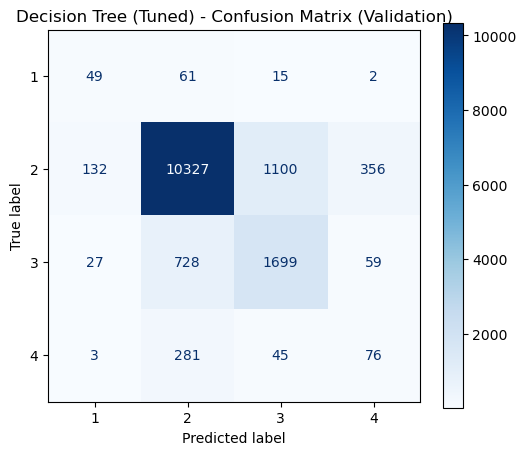

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
cm_dt = confusion_matrix(y_val, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=dt_model.classes_)
disp_dt.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title("Decision Tree (Tuned) - Confusion Matrix (Validation)")
plt.show()

In [10]:
import joblib

MODELS_DIR = PROJECT_DIR / "models"
model_path = MODELS_DIR / "decision_tree_model.pkl"

joblib.dump(best_model, model_path)

print("Decision Tree model saved to:")
print(model_path)

Decision Tree model saved to:
E:\DataMining_Group32\models\decision_tree_model.pkl
